In [117]:
import numpy as np
import matplotlib.pyplot as plt

### **SOR**

In [118]:
def SOR(A, b, omega, epsilon=0.1, max_iter=100):
    n = len(A)
    x = [0.0] * n  # Tebakan awal 0
    history = [x.copy()]
    iterasi = 1

    while iterasi <= max_iter:
        x_new = x.copy()
        
        for i in range(n):
            jumlah = 0
            for j in range(n):
                if i != j:
                    # menggunakan x_new[j] yang selalu ter-update
                    jumlah += A[i][j] * x_new[j]
            
            # Menghitung nilai x baru
            x_gs = (b[i] - jumlah) / A[i][i]
            x_new[i] = (1 - omega) * x[i] + omega * x_gs

        history.append(x_new.copy())
        
        # Mengecek konvergensi (jika selisih dengan iterasi sebelumnya lebih kecil dari epsilon)
        err = max(abs(x_new[i] - x[i]) for i in range(n))
        if err < epsilon:
            print(f"Sistem konvergen pada iterasi ke-{iterasi}")
            return x_new, history
        
        # Update nilai x untuk iterasi selanjutnya
        x = x_new

        iterasi+=1

    print("MENCAPAI BATAS ITERASI --> 100")
    return x, history

## **OUTPUT + GRAFIK**

In [119]:
# variasi omega
def realisasi(kasus):
    A,b = kasus
    omega_list = [0.2, 0.6, 1.0, 1.4, 1.8]  # contoh: 5 nilai

    for o in omega_list:
        print(f'Omega: {o}')
        solusi, history = SOR(A, b, o)
        
        print("Solusi:")
        for i in range(len(A)):
            print(f"x{i+1}: {solusi[i]}")

        # Ambil nilai
        x1_values = [h[0] for h in history]
        x2_values = [h[1] for h in history]

        # Hitung error
        error_x = []
        error_y = []

        for i in range(1, len(history)):
            error_x.append(abs(history[i][0] - history[i-1][0]))
            error_y.append(abs(history[i][1] - history[i-1][1]))

        # =========================
        # VISUALISASI
        # =========================
        fig, axs = plt.subplots(2, 2, figsize=(10, 8))

        # Judul
        fig.suptitle(f"Omega : {o}", fontsize=16)

        iterasi_x = range(1, len(x1_values)+1)
        iterasi_error = range(1, len(error_x)+1)

        # Grafik x
        axs[0,0].plot(iterasi_x, x1_values)
        axs[0,0].set_title("Nilai x per Iterasi")
        axs[0,0].set_xlabel("Iterasi")
        axs[0,0].set_ylabel("x")
        axs[0,0].grid()

        # Grafik y
        axs[0,1].plot(iterasi_x, x2_values)
        axs[0,1].set_title("Nilai y per Iterasi")
        axs[0,1].set_xlabel("Iterasi")
        axs[0,1].set_ylabel("y")
        axs[0,1].grid()

        # Error x
        axs[1,0].semilogy(iterasi_error, error_x)
        axs[1,0].set_title("Error x")
        axs[1,0].set_xlabel("Iterasi")
        axs[1,0].set_ylabel("Error")
        axs[1,0].grid()

        # Error y
        axs[1,1].semilogy(iterasi_error, error_y)
        axs[1,1].set_title("Error y")
        axs[1,1].set_xlabel("Iterasi")
        axs[1,1].set_ylabel("Error")
        axs[1,1].grid()

        # Biar ga ketiban judul atas
        plt.tight_layout(rect=[0, 0, 1, 0.95])

        plt.show()

### **KASUS 1**

Sebuah pabrik memiliki dua mesin: Mesin A dan Mesin B, yang bekerja paralel untuk memproduksi dua jenis produk: Produk 1 dan Produk 2.
Untuk Produk 1, Mesin A mendominasi produksi dengan rasio 8:1 terhadap Mesin B. Total produksi Produk 1 adalah 36 unit.
Untuk Produk 2, Mesin B mendominasi produksi dengan rasio 1:5 terhadap Mesin A. Total produksi Produk 2 adalah 30 unit.

Misalkan:

$x_1$ = kapasitas produksi Mesin A

$x_2$ = kapasitas produksi Mesin B

Model SPL:
$$
\begin{cases}
8x_1 + x_2 = 36 \\
x_1 + 5x_2 = 30
\end{cases}
$$

Ubah ke bentuk Matriks:

$$
\begin{bmatrix}
8 & 1 \\
1 & 5
\end{bmatrix}
\begin{bmatrix}
x_1 \\
x_2
\end{bmatrix}
=
\begin{bmatrix}
36 \\
30
\end{bmatrix}
$$

$$
A =
\begin{bmatrix}
8 & 1 \\
1 & 5
\end{bmatrix}
$$

$$
b =
\begin{bmatrix}
36 \\
30
\end{bmatrix}
$$

Omega: 0.2
Sistem konvergen pada iterasi ke-11
Solusi:
x1: 3.6511446402237437
x2: 4.892905077681133


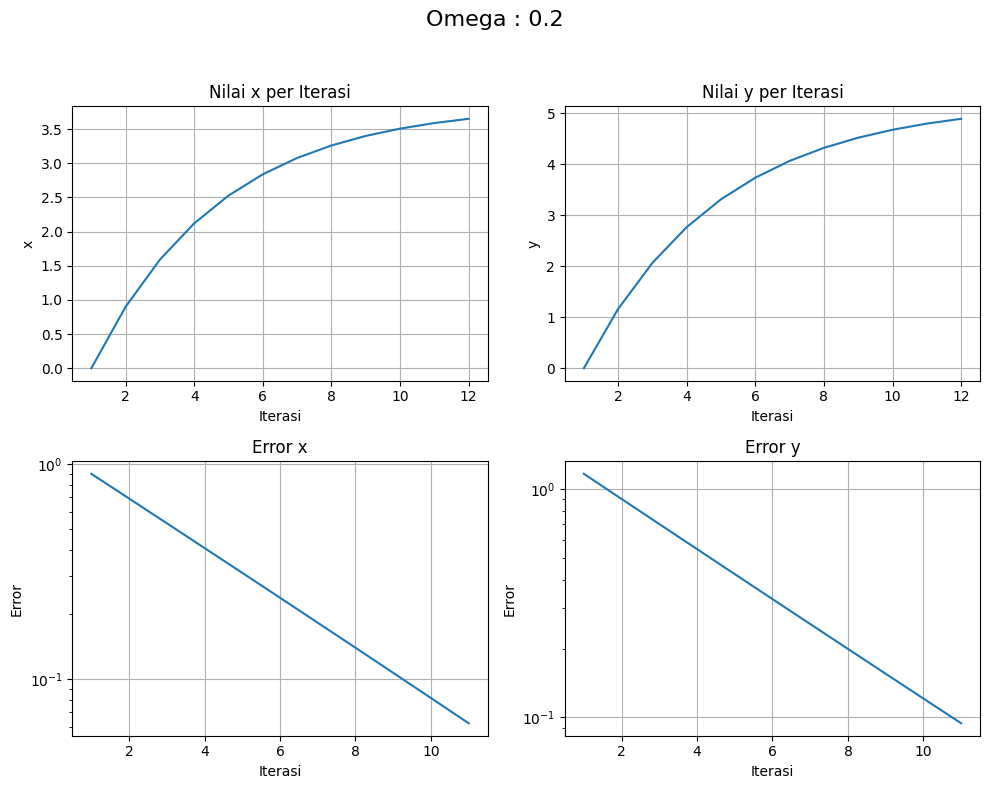

Omega: 0.6
Sistem konvergen pada iterasi ke-5
Solusi:
x1: 3.8524479224247004
x2: 5.183970552750636


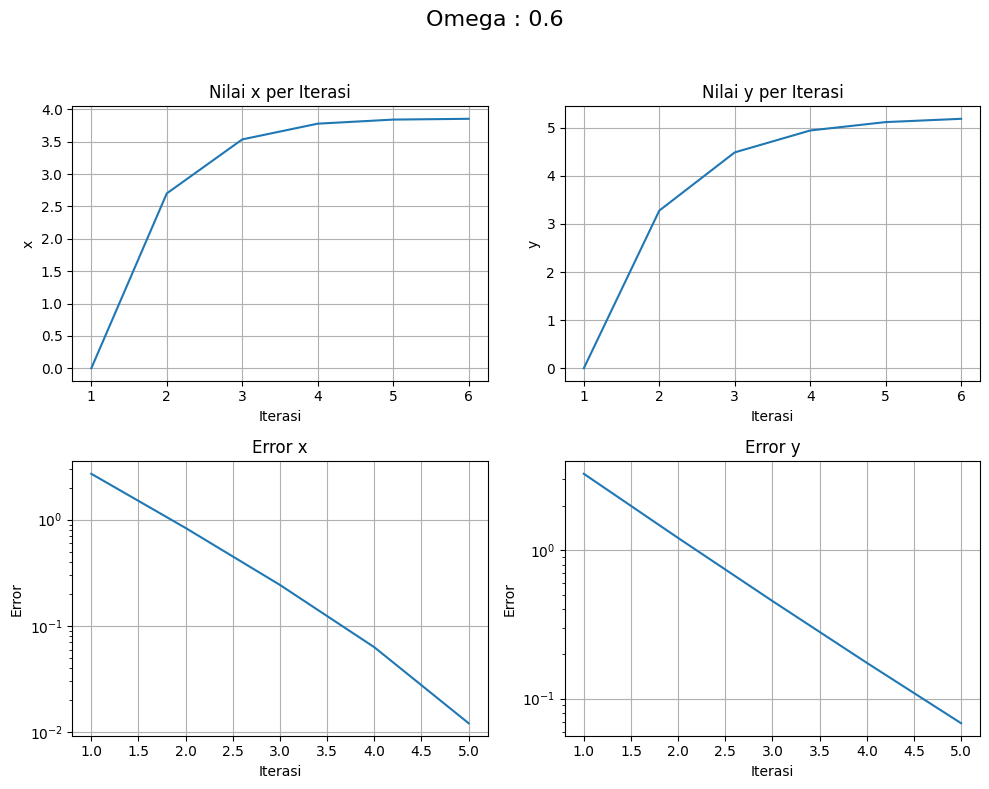

Omega: 1.0
Sistem konvergen pada iterasi ke-3
Solusi:
x1: 3.8465625
x2: 5.2306875


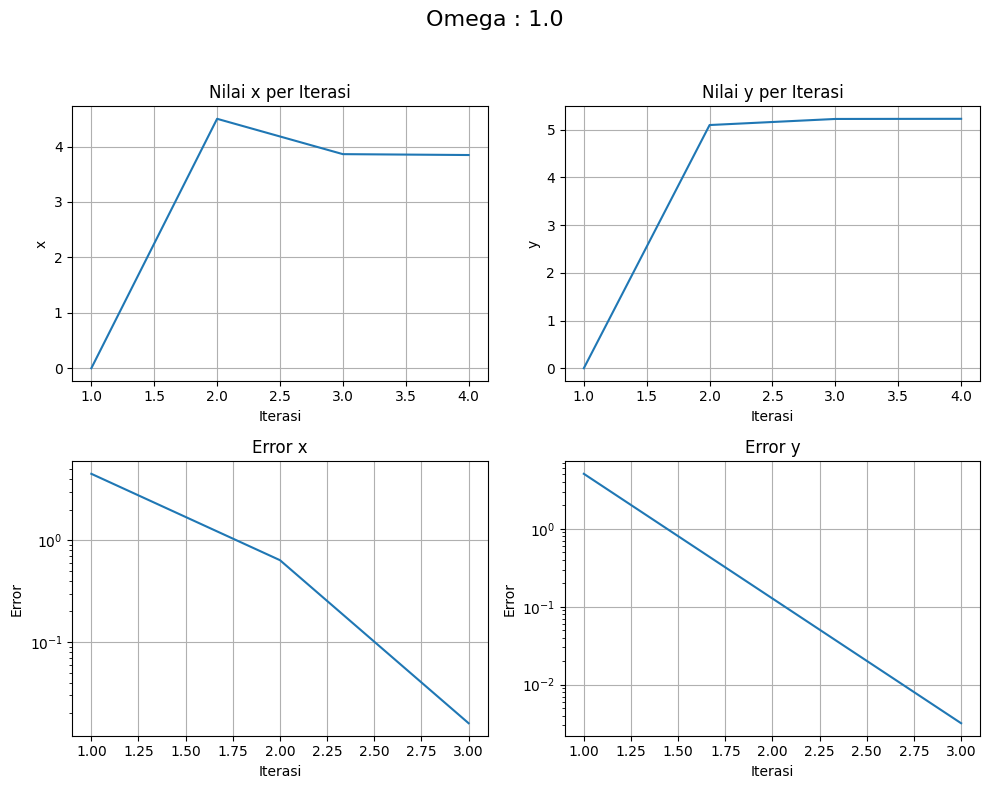

Omega: 1.4
Sistem konvergen pada iterasi ke-6
Solusi:
x1: 3.828523087278219
x2: 5.256030935106644


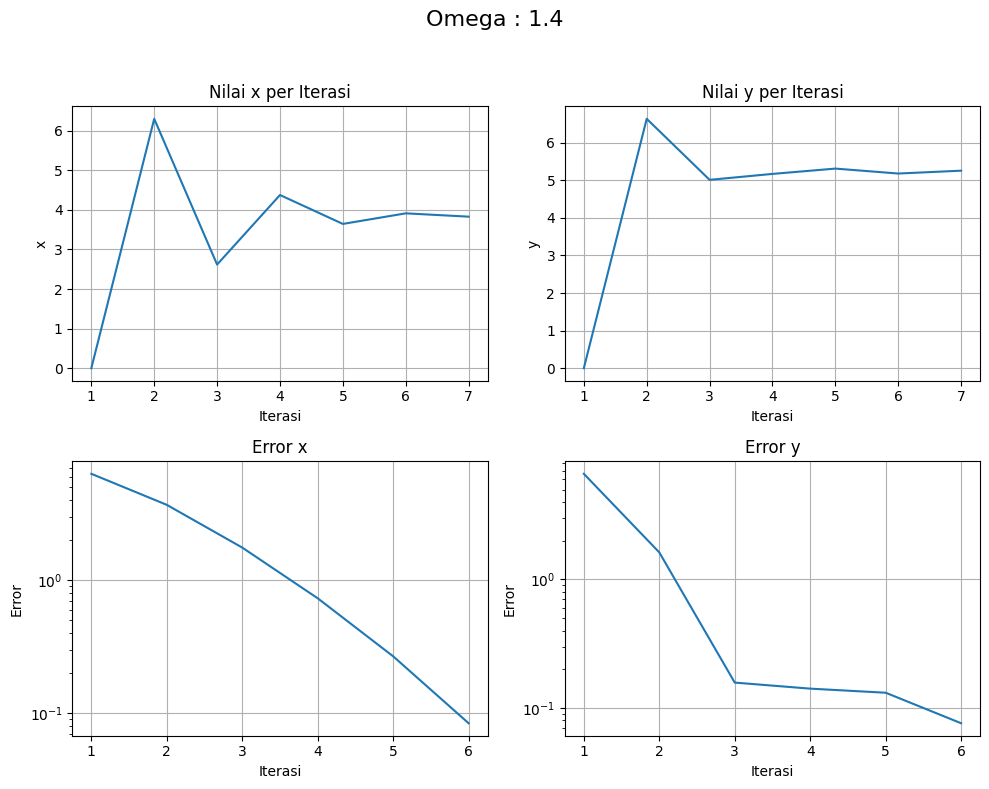

Omega: 1.8
Sistem konvergen pada iterasi ke-22
Solusi:
x1: 3.7987451685534057
x2: 5.228775356444074


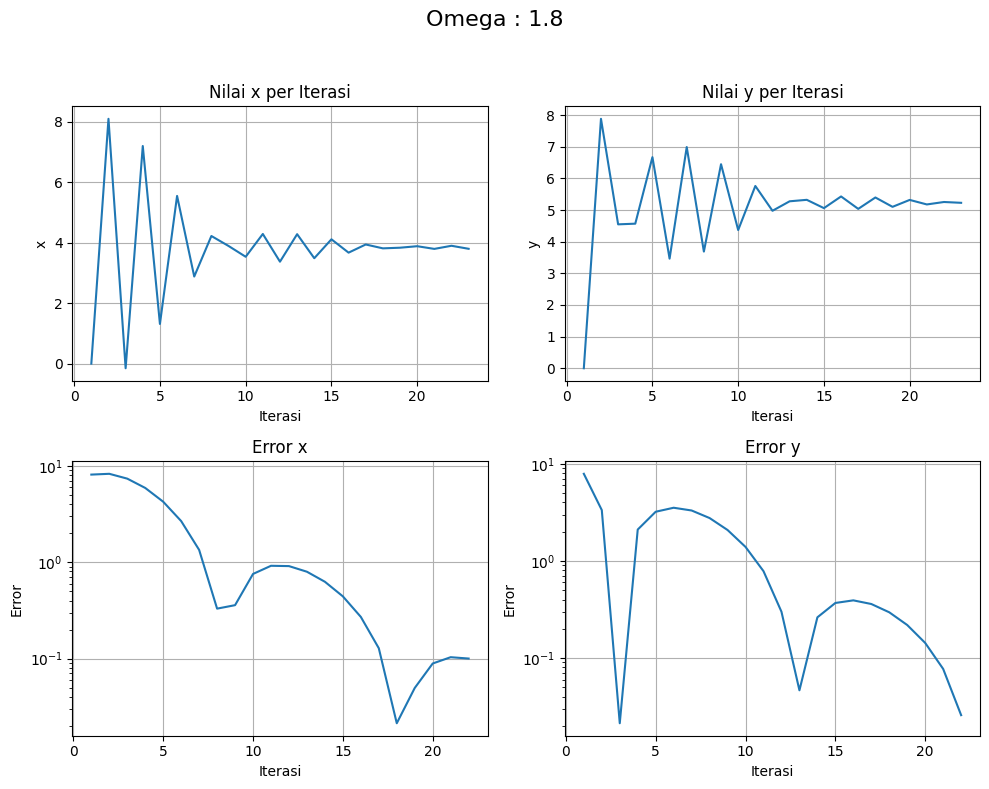

In [120]:
#Matriks A
A = np.array([
    [8, 1],
    [1, 5]
], dtype=float)

#Matriks b
b = np.array([36, 30], dtype=float)

kasus1 = (A,b)

realisasi(kasus1)

## KASUS 2

Dalam program Makan Bergizi Gratis (MBG), sebuah tim ahli gizi ingin menentukan komposisi nutrisi ideal dalam satu porsi makanan.

Tiga komponen utama yang diperhatikan adalah:

* Protein
* Karbohidrat
* Lemak

---

### Diketahui

Setiap gram nutrisi menghasilkan energi sebagai berikut:

* Protein: 4 kkal/gram
* Karbohidrat: 4 kkal/gram
* Lemak: 9 kkal/gram

Total energi yang ditargetkan dalam satu porsi adalah:
$$
500 \text{ kkal}
$$

---

Selain itu, ditentukan proporsi kebutuhan gizi sebagai berikut:

* Total massa nutrisi:
  $$
  x_1 + 4x_2 + x_3 = 100
  $$

* Protein dan karbohidrat bersama-sama harus mencapai:
  $$
  3x_1 + x_2 = 70
  $$

---

### Misalkan

$$
x_1 = \text{protein (gram)}
$$
$$
x_2 = \text{karbohidrat (gram)}
$$
$$
x_3 = \text{lemak (gram)}
$$

---

### Model SPL

$$
\begin{cases}
3x_1 + x_2 = 70 \\
x_1 + 4x_2 + x_3 = 100 \\
4x_1 + 4x_2 + 9x_3 = 500 
\end{cases}
$$

---

### Bentuk Matriks

$$
\begin{bmatrix}
3 & 1 & 0 \\
1 & 4 & 1 \\
4 & 4 & 9 
\end{bmatrix}

\begin{bmatrix}
x_3 \\
x_2 \\
x_1 
\end{bmatrix}
=

\begin{bmatrix}
70 \\
100 \\
500 
\end{bmatrix}
$$

---

### Definisi Matriks

$$
A =
\begin{bmatrix}
3 & 1 & 0 \\
1 & 4 & 1 \\
4 & 4 & 9 
\end{bmatrix}
$$

$$
b =
\begin{bmatrix}
70 \\
100 \\
500 
\end{bmatrix}
$$


In [121]:
#Kasus 2
A = np.array([
    [3, 1, 0],
    [1, 4, 1],
    [4, 4, 9]
], dtype= float)

b = np.array([
    70,
    100,
    500
], dtype= float)

kasus2 = (A, b)

Omega: 0.2
Sistem konvergen pada iterasi ke-11
Solusi:
x1: 3.6511446402237437
x2: 4.892905077681133


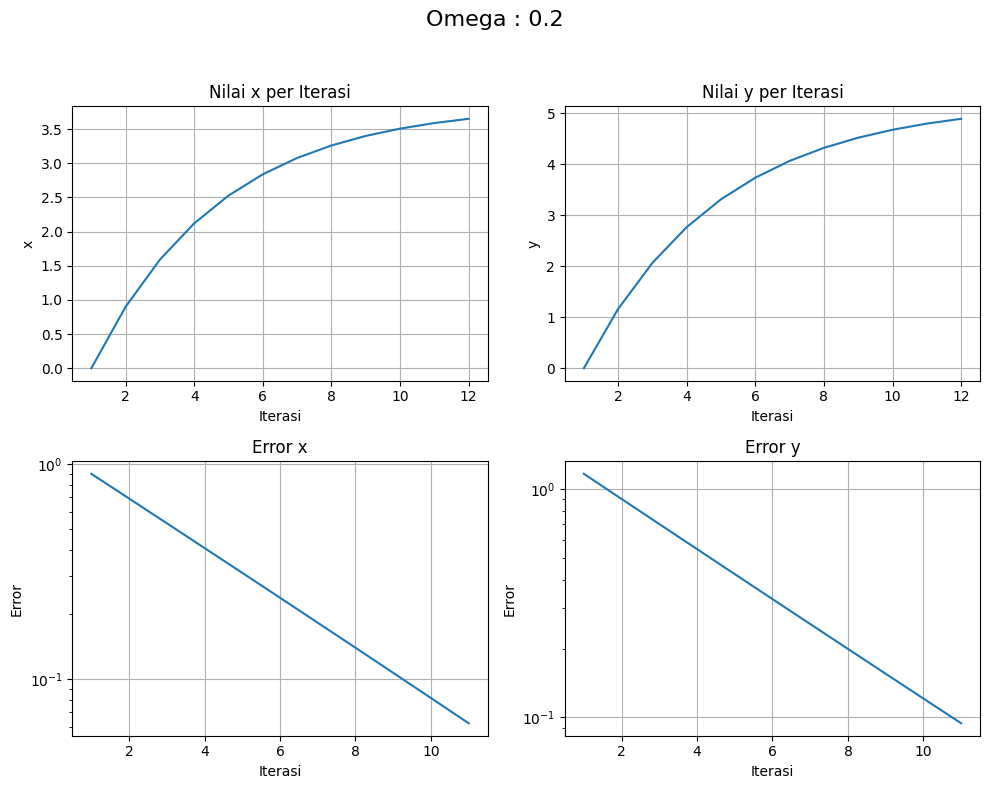

Omega: 0.6
Sistem konvergen pada iterasi ke-5
Solusi:
x1: 3.8524479224247004
x2: 5.183970552750636


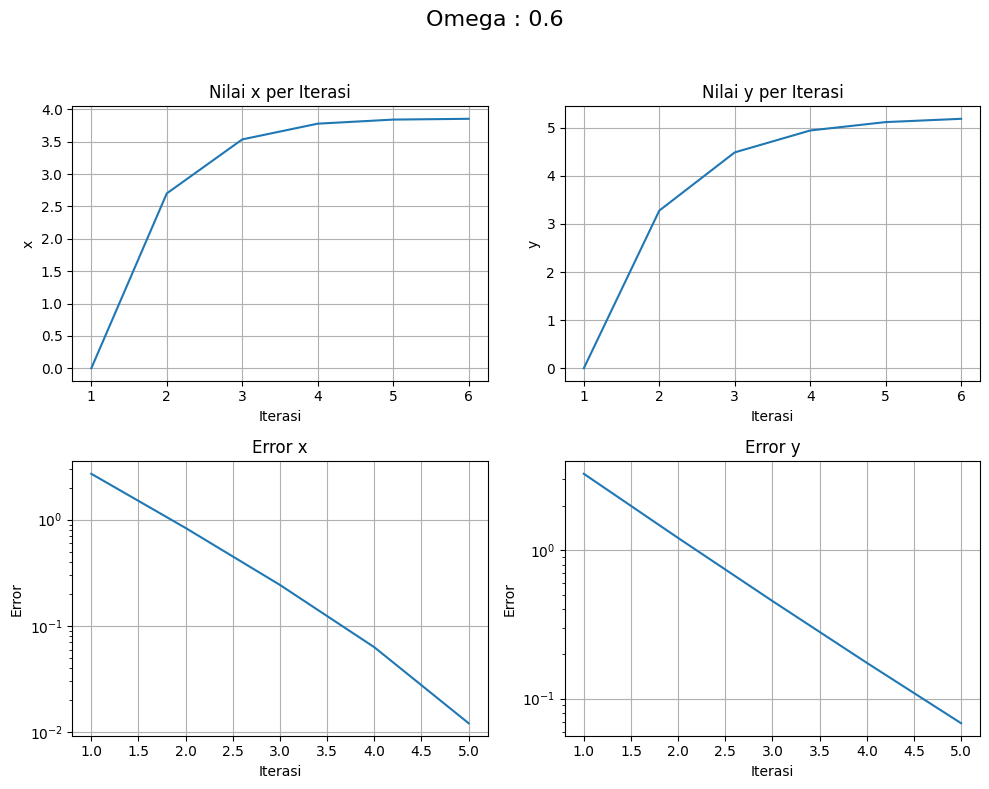

Omega: 1.0
Sistem konvergen pada iterasi ke-3
Solusi:
x1: 3.8465625
x2: 5.2306875


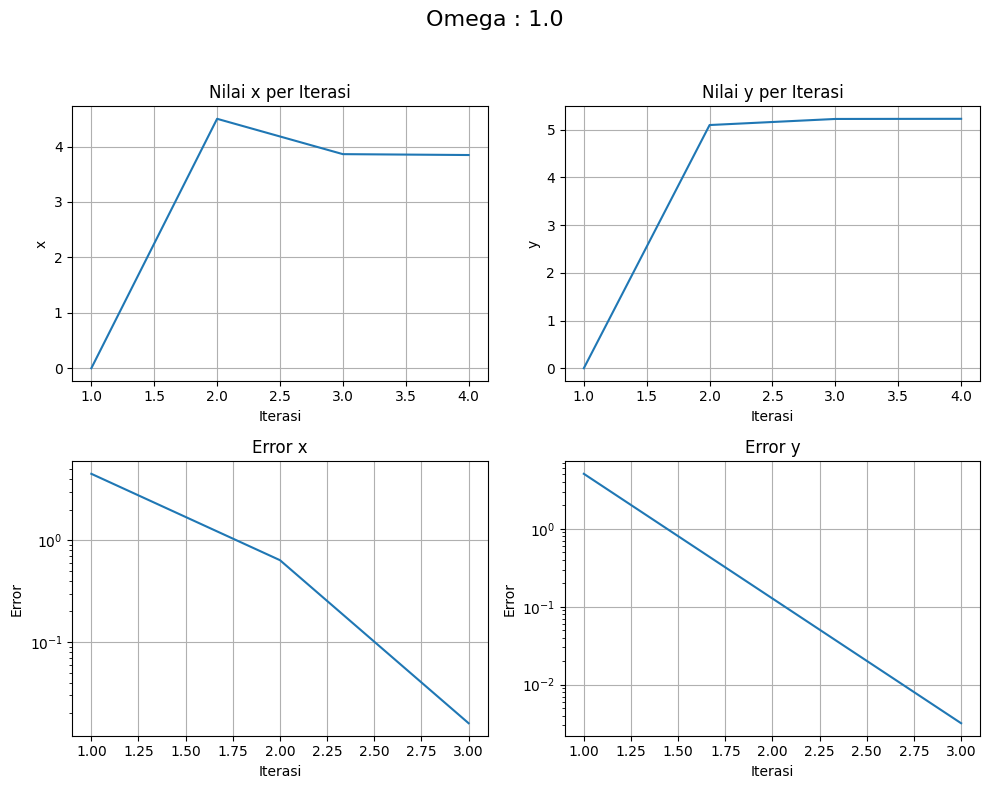

Omega: 1.4
Sistem konvergen pada iterasi ke-6
Solusi:
x1: 3.828523087278219
x2: 5.256030935106644


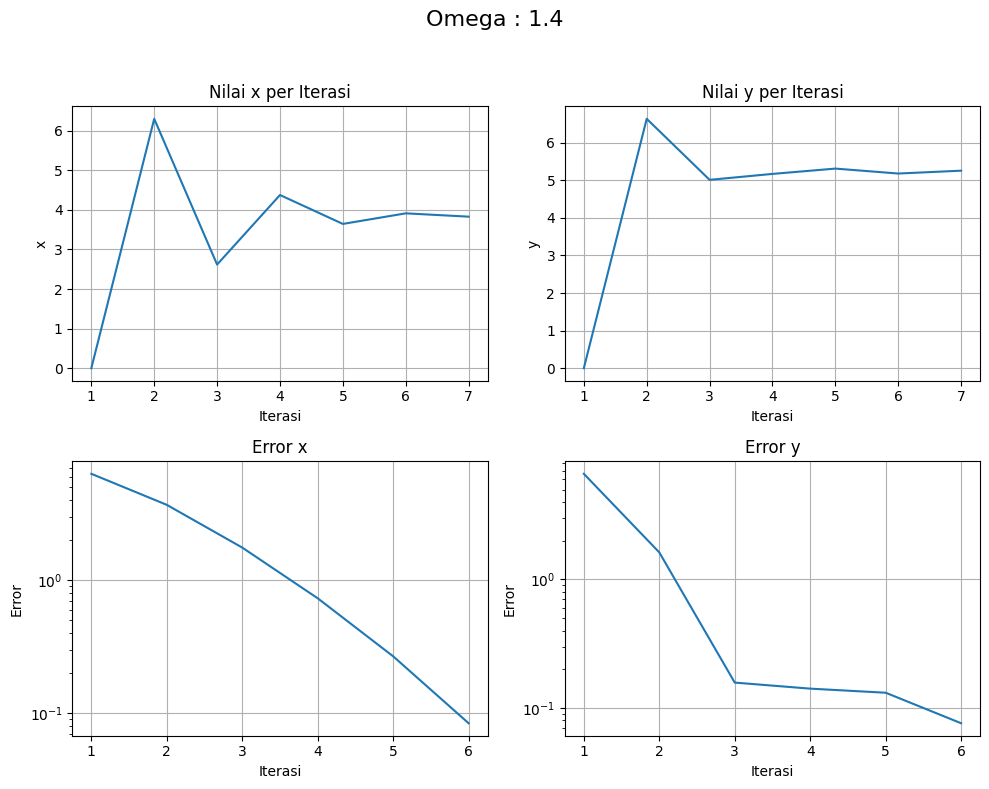

Omega: 1.8
Sistem konvergen pada iterasi ke-22
Solusi:
x1: 3.7987451685534057
x2: 5.228775356444074


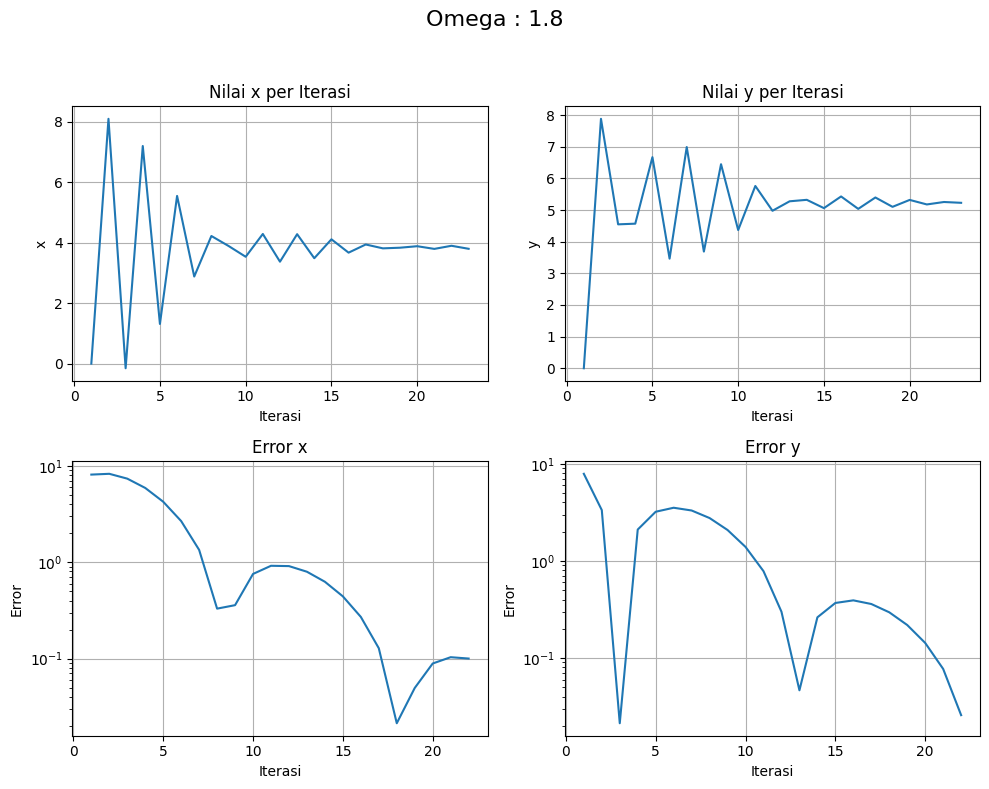

In [122]:
realisasi(kasus1)

Omega: 0.2
Sistem konvergen pada iterasi ke-21
Solusi:
x1: 19.630879705149784
x2: 9.984141709486746
x3: 42.08696891724243


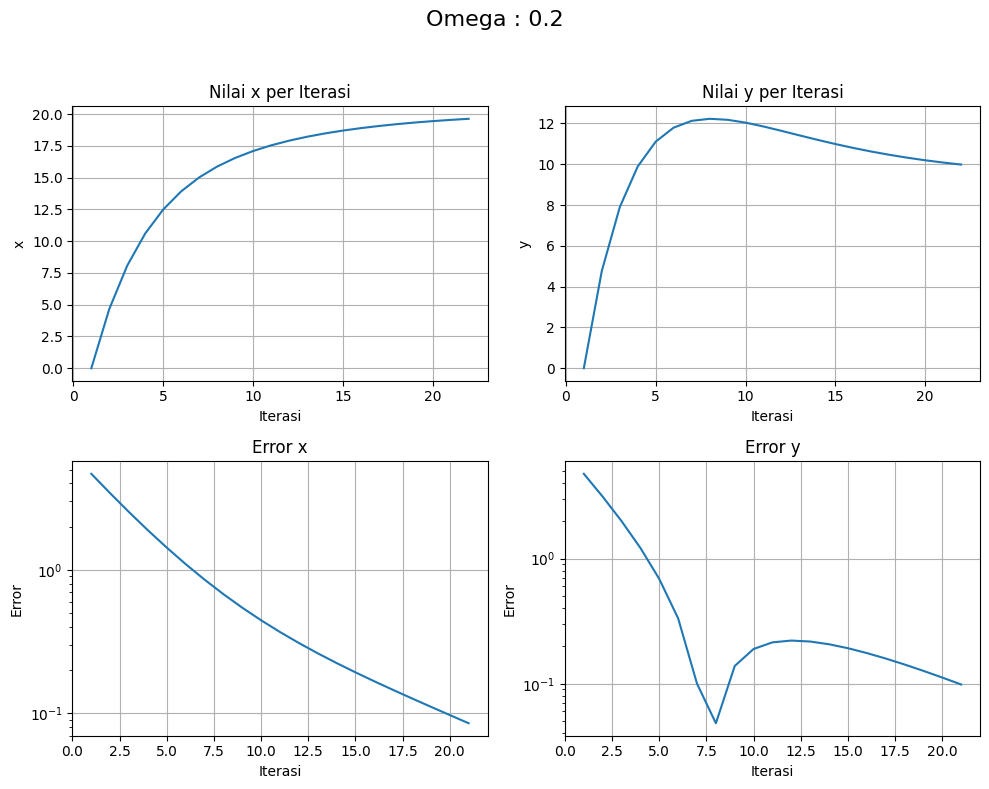

Omega: 0.6
Sistem konvergen pada iterasi ke-9
Solusi:
x1: 20.09885510508905
x2: 9.43341782449158
x3: 42.41589579956716


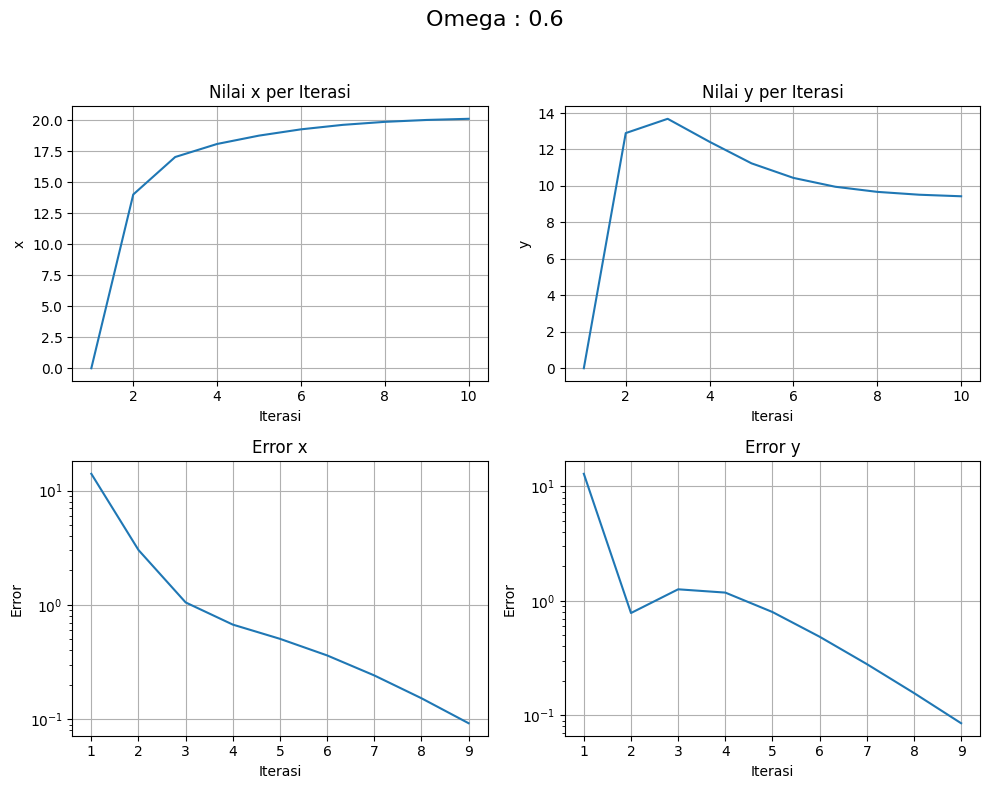

Omega: 1.0
Sistem konvergen pada iterasi ke-5
Solusi:
x1: 20.242787637174214
x2: 9.324466127972109
x3: 42.41455388215719


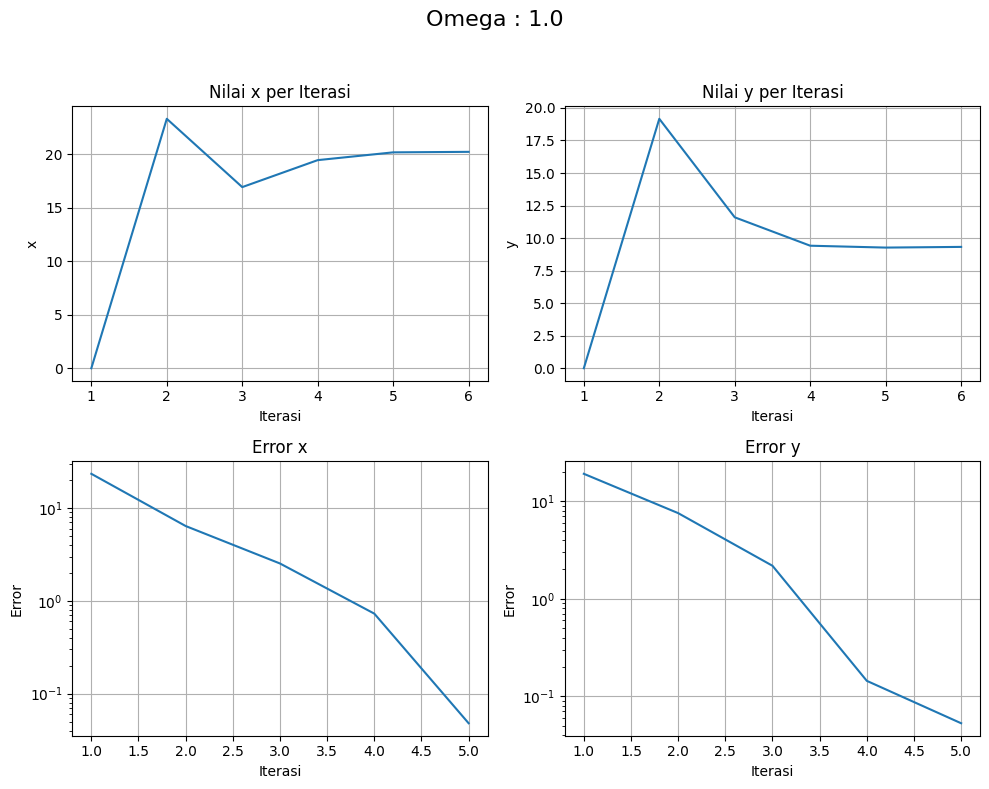

Omega: 1.4
Sistem konvergen pada iterasi ke-12
Solusi:
x1: 20.245469671441683
x2: 9.336135023279857
x3: 42.394007205583414


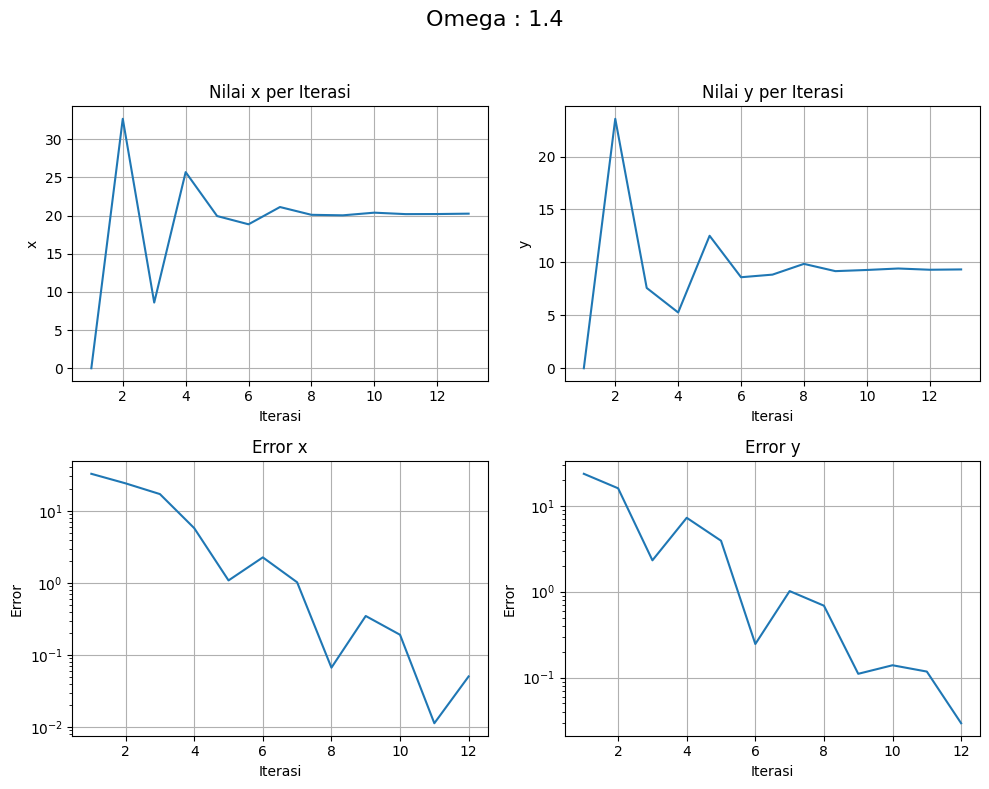

Omega: 1.8
MENCAPAI BATAS ITERASI --> 100
Solusi:
x1: 18.160240813727484
x2: 0.30407682032761585
x3: 47.16763997220772


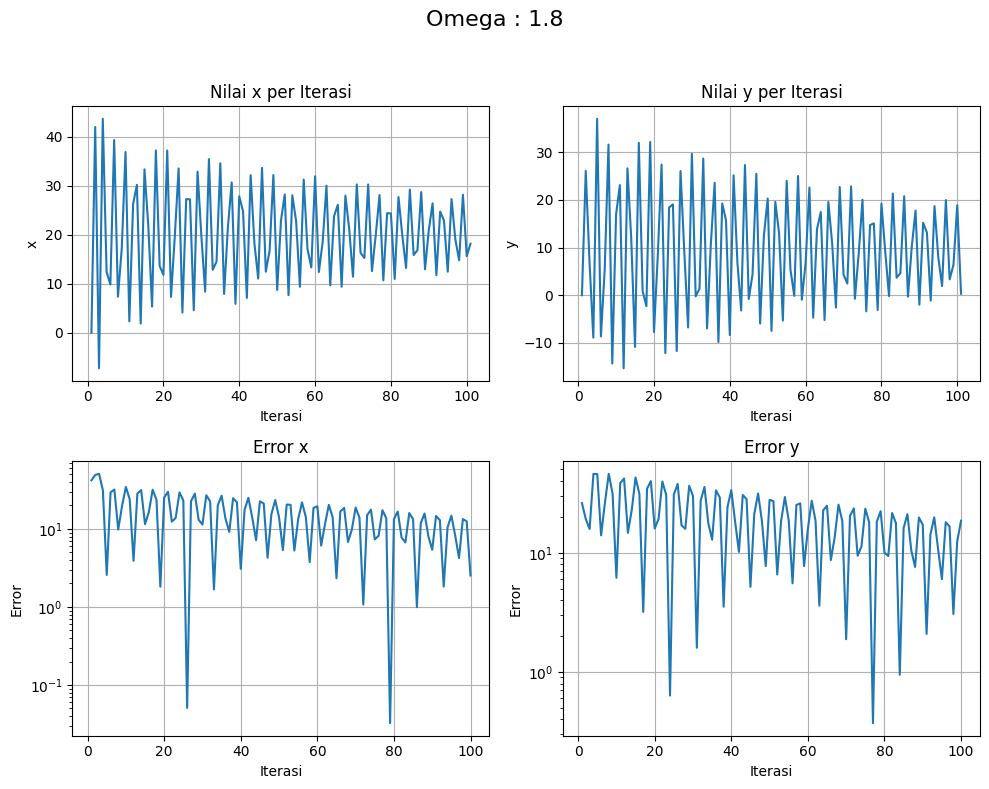

In [123]:
realisasi(kasus2)